In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import h5py
import matplotlib.pyplot as plt
from scipy.signal import welch

In [2]:
# pulling Machine-2 Data from the data directory (Machine-2 is identified as M01 in the data directory)
data_dir = Path("/Users/tusar/Desktop/Leuphana courses/winter 2026/Smart Sensor Systems/CNC_Machining-main/data/M01/OP01")


print("folder exists:", data_dir.exists())

folder exists: True


In [3]:
for sub in sorted(data_dir.iterdir()):
    if sub.is_dir():
        files = sorted(sub.glob("*.h5"))
        print(f"{sub.name}:{len(files)} files")
        for f in files[:10]:
            print(f"  {f.name}")
        

bad:2 files
  M01_Aug_2019_OP01_000.h5
  M01_Feb_2019_OP01_000.h5
good:38 files
  M01_Aug_2019_OP01_000.h5
  M01_Aug_2019_OP01_001.h5
  M01_Aug_2019_OP01_002.h5
  M01_Aug_2019_OP01_003.h5
  M01_Aug_2019_OP01_004.h5
  M01_Aug_2019_OP01_005.h5
  M01_Aug_2019_OP01_006.h5
  M01_Aug_2019_OP01_007.h5
  M01_Aug_2019_OP01_008.h5
  M01_Aug_2019_OP01_009.h5


In [4]:
# checking the folder structure and the number of files in each subfolder

good_files = sorted((data_dir / "good").glob("*.h5"))
bad_files  = sorted((data_dir / "bad").glob("*.h5"))
print(len(good_files), "good,", len(bad_files), "bad")

first = good_files[0]
print("\nopening:", first.name)

with h5py.File(first, "r") as f:
    print("datasets inside:", list(f.keys()))
    d = f["vibration_data"]
    print("shape:", d.shape)
    print("dtype:", d.dtype)
    signal = d[:]          # this is the line that actually reads it into memory

print("\nin memory:", type(signal), signal.shape)
print(signal[:5])

38 good, 2 bad

opening: M01_Aug_2019_OP01_000.h5
datasets inside: ['vibration_data']
shape: (60416, 3)
dtype: float64

in memory: <class 'numpy.ndarray'> (60416, 3)
[[  -15.    23. -1018.]
 [   -7.    15. -1016.]
 [   -7.    19. -1009.]
 [  -15.    27. -1016.]
 [  -17.    35. -1015.]]


In [5]:
FS = 2000
GOOD_C, BAD_C = "#2E6F9E", "#B3322C"

def spectrum(x, fs=FS, nperseg=1024):
    f, P = welch(x - x.mean(), fs=fs, nperseg=nperseg, noverlap=nperseg // 2)
    return f, P

def top_peak(f, P, fmin=30):
    m = f >= fmin
    return f[m][np.argmax(P[m])]

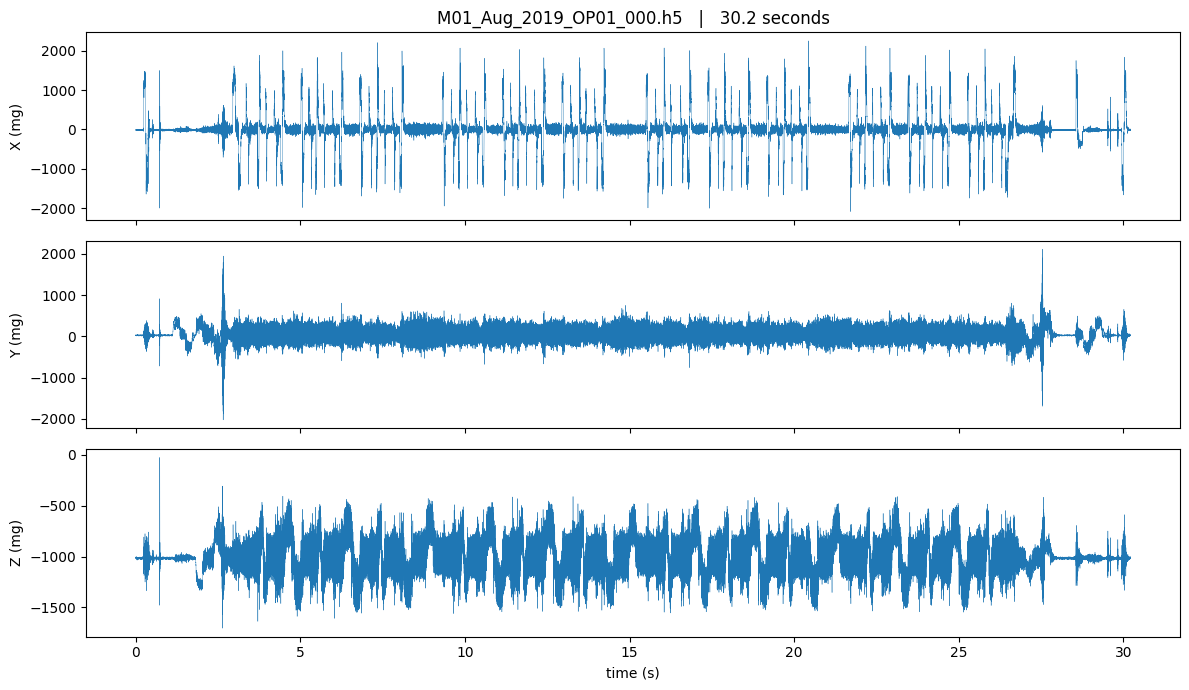

In [6]:
# observing the frequency of process one

FS = 2000                                   # samples per second, per axis
t = np.arange(signal.shape[0]) / FS         # a time axis in seconds

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for i, name in enumerate(["X", "Y", "Z"]):
    axes[i].plot(t, signal[:, i], lw=0.3)
    axes[i].set_ylabel(f"{name} (mg)")
axes[-1].set_xlabel("time (s)")
axes[0].set_title(f"{first.name}   |   {signal.shape[0]/FS:.1f} seconds")
plt.tight_layout()
plt.show()

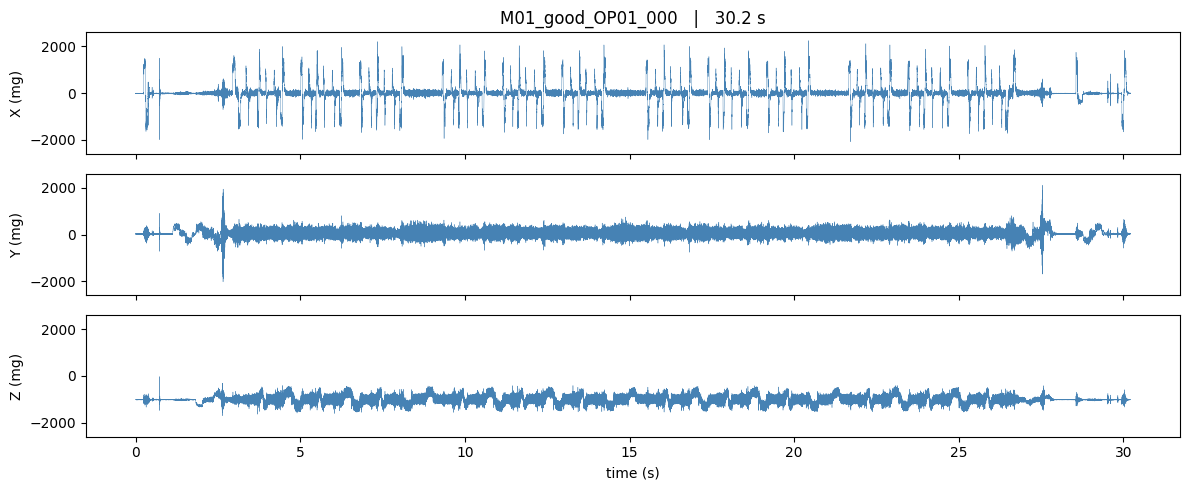

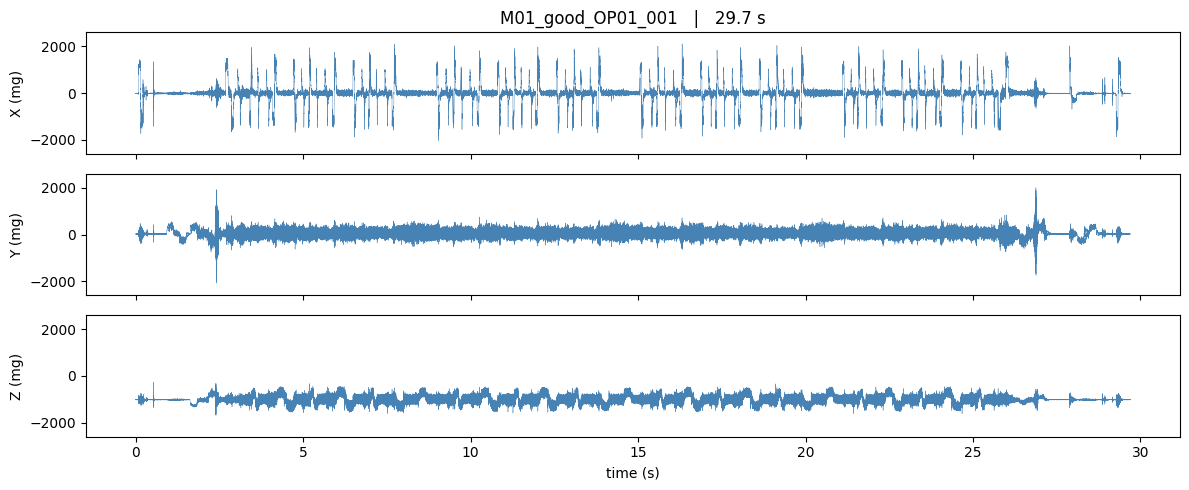

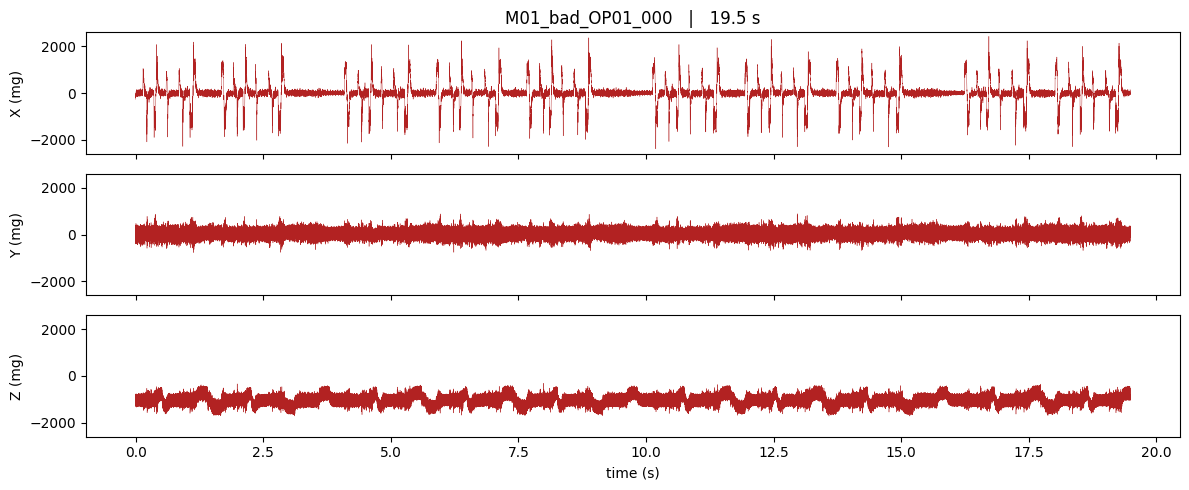

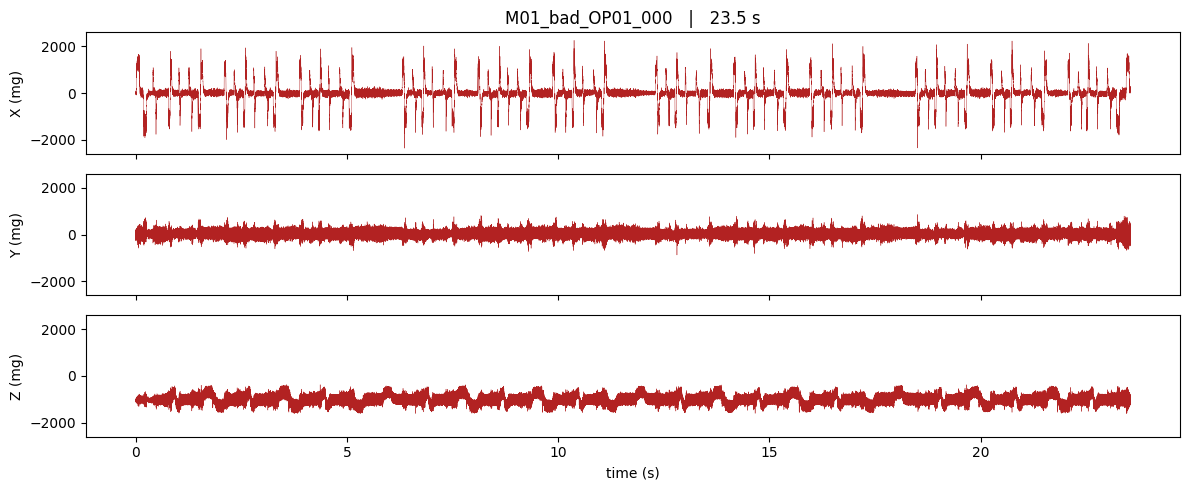

In [7]:
# trying to plot visuals to understand the difference between good and bad files

N_PER_CLASS = 2

def make_title(path, label):
    parts = path.stem.split("_")      # ['M01', 'Aug', '2019', 'OP01', '000']
    return f"{parts[0]}_{label}_{parts[-2]}_{parts[-1]}"

selection = ([(p, "good") for p in good_files[:N_PER_CLASS]]
           + [(p, "bad")  for p in bad_files[:N_PER_CLASS]])

for path, label in selection:
    with h5py.File(path, "r") as f:
        sig = f["vibration_data"][:]

    t = np.arange(sig.shape[0]) / FS

    fig, axes = plt.subplots(3, 1, figsize=(12, 5), sharex=True)
    for i, ax_name in enumerate(["X", "Y", "Z"]):
        axes[i].plot(t, sig[:, i], lw=0.3, color="firebrick" if label == "bad" else "steelblue")
        axes[i].set_ylabel(f"{ax_name} (mg)")
        axes[i].set_ylim(-2600, 2600)      # same scale on every figure
    axes[-1].set_xlabel("time (s)")
    axes[0].set_title(f"{make_title(path, label)}   |   {sig.shape[0]/FS:.1f} s")
    plt.tight_layout()
    plt.show()
    plt.close(fig)

What is seen that the good ones trends to keep a consistent frequency in all three processes in all three axises but in the bad signals they treds to change the frequency noises.

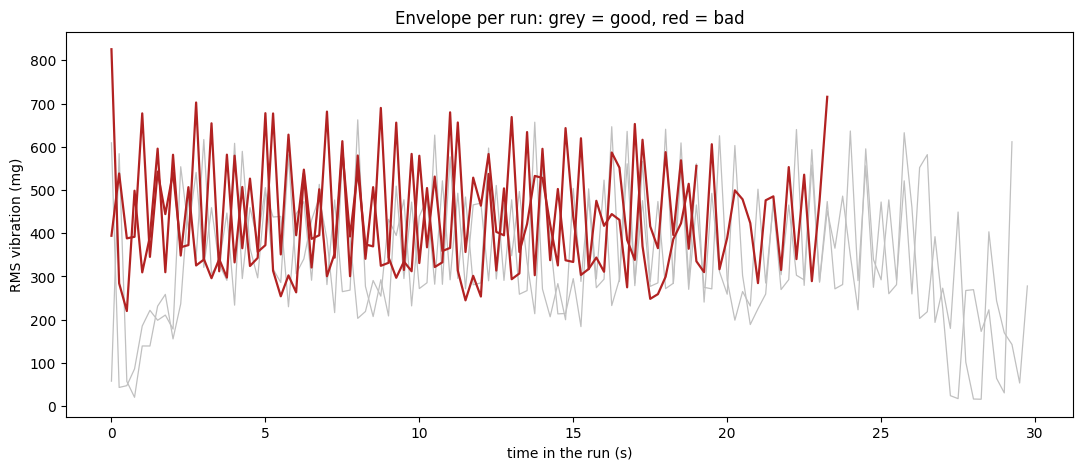

In [8]:
# Now checking the envelope of the signal, which is a measure of the overall vibration magnitude over time

def envelope(sig, win_s=0.25):
    w = int(win_s * FS)
    n = (len(sig) // w) * w
    x = sig[:n] - sig[:n].mean(axis=0)        # drop the DC offset, including gravity on Z
    mag = np.sqrt((x ** 2).sum(axis=1))       # combine X, Y, Z into one magnitude
    return mag.reshape(-1, w).mean(axis=1)    # average inside each 0.25 s window

plt.figure(figsize=(13, 5))
for path, label in selection:
    with h5py.File(path, "r") as f:
        sig = f["vibration_data"][:]
    e = envelope(sig)
    t = np.arange(len(e)) * 0.25
    plt.plot(t, e,
             color="firebrick" if label == "bad" else "silver",
             lw=1.6 if label == "bad" else 0.9,
             zorder=3 if label == "bad" else 1)

plt.xlabel("time in the run (s)")
plt.ylabel("RMS vibration (mg)")
plt.title("Envelope per run: grey = good, red = bad")
plt.show()

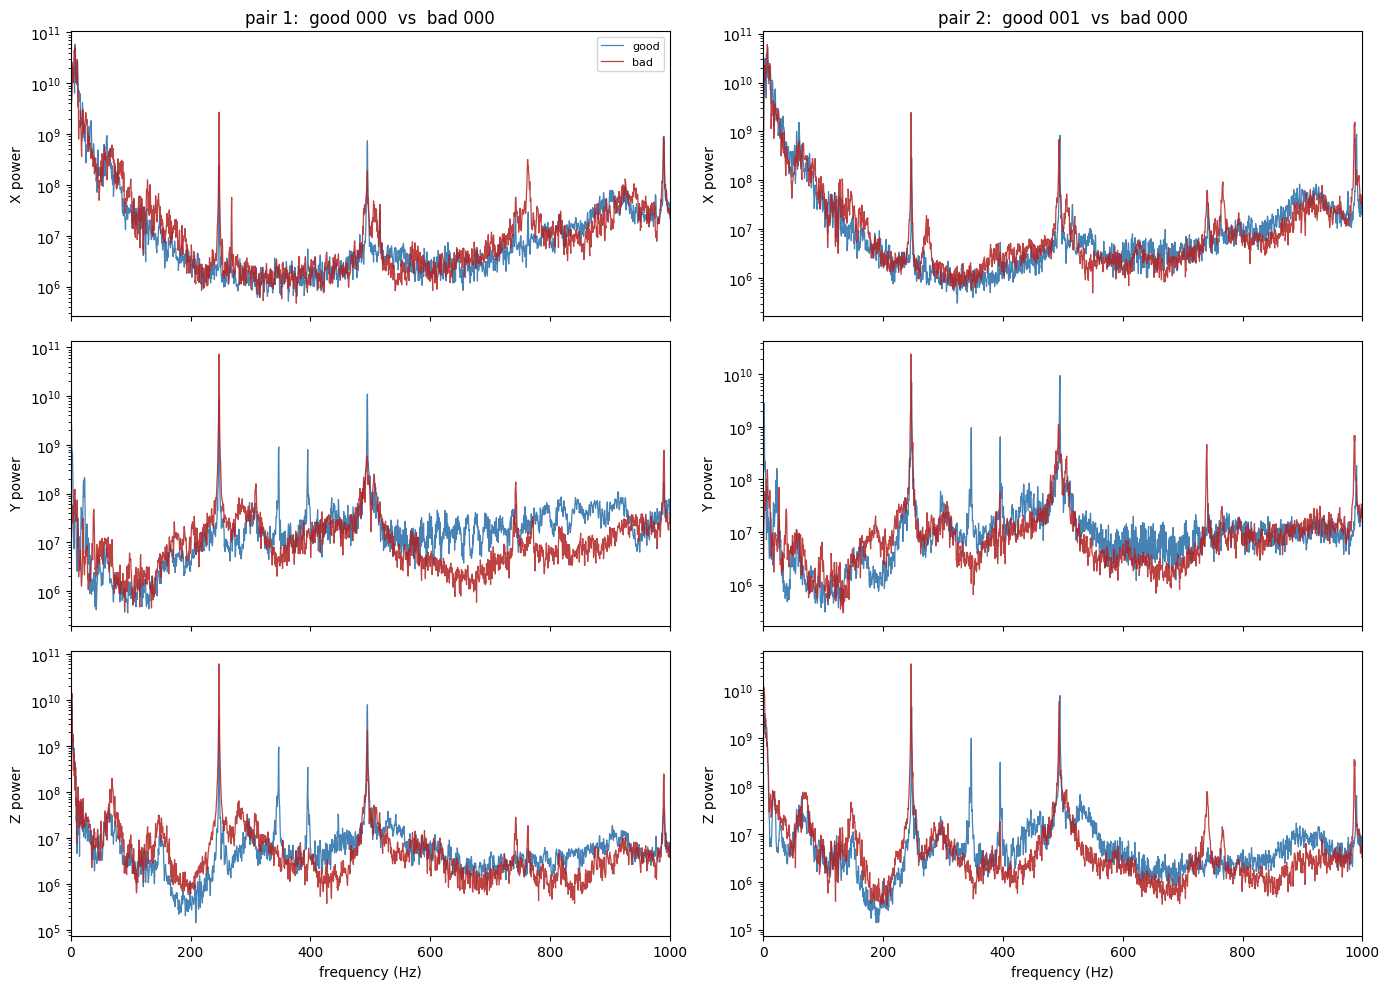

In [9]:
# defining two observations (good and bad) and comparing their frequency spectra so that we can see the direct difference at a glance

def spectrum(x, fs=FS, nfft=4096):
    x = x - x.mean()
    n = (len(x) // nfft) * nfft
    seg = x[:n].reshape(-1, nfft) * np.hanning(nfft)   # split into chunks, taper each
    P = (np.abs(np.fft.rfft(seg, axis=1)) ** 2).mean(axis=0)
    f = np.fft.rfftfreq(nfft, 1 / fs)
    return f, P

pairs = list(zip(good_files[:2], bad_files[:2]))

fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharex=True)

for col, (gpath, bpath) in enumerate(pairs):
    with h5py.File(gpath, "r") as f: g = f["vibration_data"][:]
    with h5py.File(bpath, "r") as f: b = f["vibration_data"][:]

    for i, nm in enumerate(["X", "Y", "Z"]):
        fg, Pg = spectrum(g[:, i])
        fb, Pb = spectrum(b[:, i])
        ax = axes[i, col]
        ax.semilogy(fg, Pg, color="steelblue", lw=0.9, label="good")
        ax.semilogy(fb, Pb, color="firebrick", lw=0.9, alpha=0.85, label="bad")
        ax.set_ylabel(f"{nm} power")
        ax.set_xlim(0, 1000)

    axes[0, col].set_title(f"pair {col+1}:  good {gpath.stem.split('_')[-1]}  vs  bad {bpath.stem.split('_')[-1]}")

axes[0, 0].legend(fontsize=8)
for c in range(2):
    axes[-1, c].set_xlabel("frequency (Hz)")
plt.tight_layout()
plt.show()

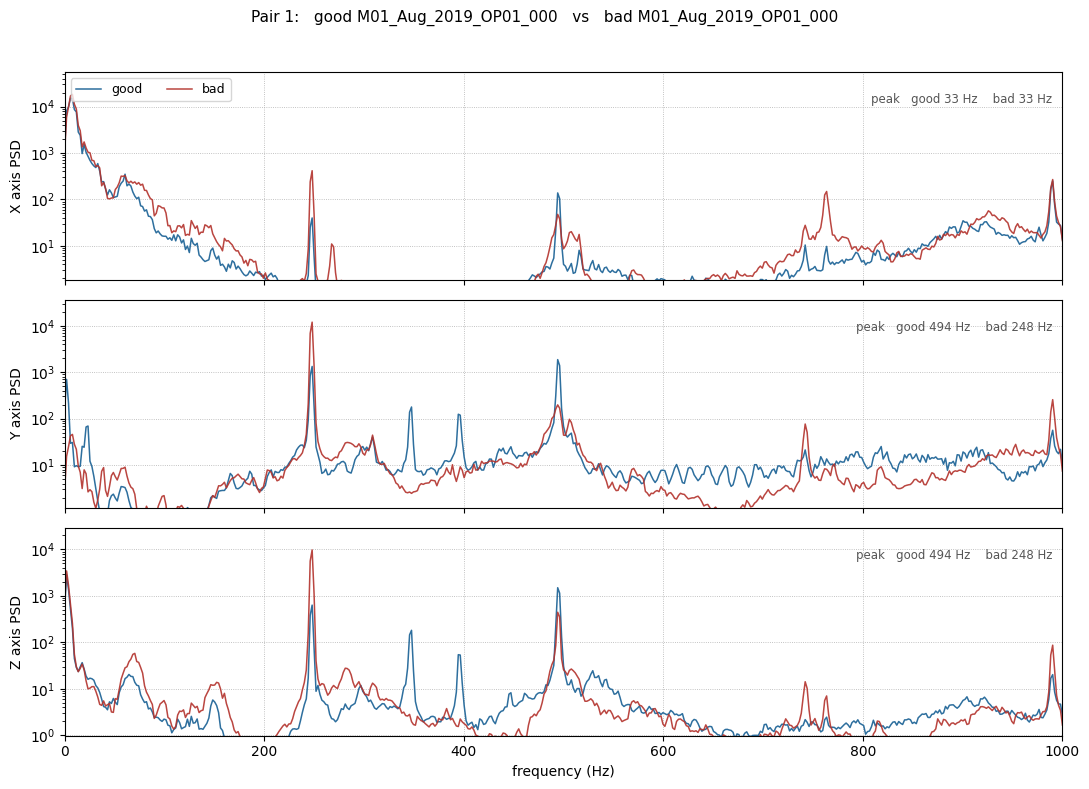

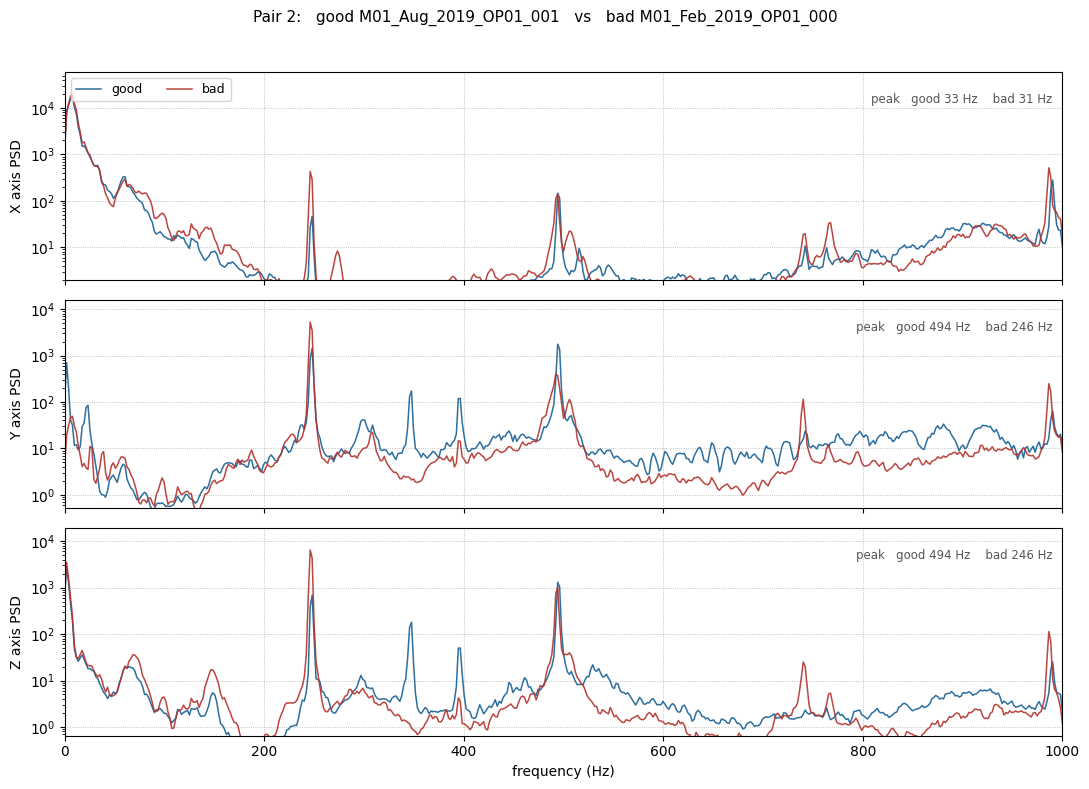

In [10]:
# seperating the spectrum function to use scipy's welch method for better frequency resolution and averaging
GOOD_C, BAD_C = "#2E6F9E", "#B3322C"

def spectrum(x, fs=FS, nperseg=1024):
    f, P = welch(x - x.mean(), fs=fs, nperseg=nperseg, noverlap=nperseg // 2)
    return f, P

pairs = list(zip(good_files[:2], bad_files[:2]))

for n, (gpath, bpath) in enumerate(pairs, start=1):
    with h5py.File(gpath, "r") as f: g = f["vibration_data"][:]
    with h5py.File(bpath, "r") as f: b = f["vibration_data"][:]

    fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

    for i, nm in enumerate(["X", "Y", "Z"]):
        ax = axes[i]
        fg, Pg = spectrum(g[:, i])
        fb, Pb = spectrum(b[:, i])

        ax.semilogy(fg, Pg, color=GOOD_C, lw=1.1, label="good")
        ax.semilogy(fb, Pb, color=BAD_C,  lw=1.1, label="bad", alpha=0.9)

        hi = max(Pg.max(), Pb.max())
        ax.set_ylim(hi / 1e4, hi * 3)          # four decades below the loudest point
        ax.set_xlim(0, 1000)
        ax.set_ylabel(f"{nm} axis PSD")
        ax.grid(True, ls=":", lw=0.6)
        ax.text(0.99, 0.90,
                f"peak   good {top_peak(fg, Pg):.0f} Hz    bad {top_peak(fb, Pb):.0f} Hz",
                transform=ax.transAxes, ha="right", va="top",
                fontsize=8.5, color="#555555")

    axes[0].legend(loc="upper left", ncol=2, fontsize=9)
    axes[-1].set_xlabel("frequency (Hz)")
    fig.suptitle(f"Pair {n}:   good {gpath.stem}   vs   bad {bpath.stem}", fontsize=11)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()
    plt.close(fig)

The two blue (good) pictures look consistent with each other. The same peaks show up at the same places in both, around 248, 345, 395 and 494 Hz. The red (bad) ones are not stable like that. The spikes in bad are much higher, especially at 248 Hz, and some peaks go missing while new ones appear, like the one near 740 Hz. Bad is also never the same as good on any axis. It is either higher or lower, so the frequency pattern is always off from the normal one. These are the anomalies we can see.